In [1]:
!pip install -q ultralytics
!pip install -q deep-sort-realtime
!pip install -q torchmetrics
!pip install -q kaggle
print("All packages installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 66.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 100.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 58.1 MB/s eta 0:00:00
All packages installed.


In [2]:
import os
import cv2
import json
import time
import random
import io
import warnings
import functools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image
from tqdm import tqdm
from collections import defaultdict

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights,
    ssdlite320_mobilenet_v3_large, SSDLite320_MobileNet_V3_Large_Weights,
)
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.ssdlite import SSDLiteClassificationHead

warnings.filterwarnings('ignore')

from ultralytics import YOLO
from deep_sort_realtime.deepsort_tracker import DeepSort

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

VISDRONE_CLASSES = [
    'pedestrian', 'people', 'bicycle', 'car', 'van',
    'truck', 'tricycle', 'awning-tricycle', 'bus', 'motor',
]
NUM_CLASSES = len(VISDRONE_CLASSES) + 1

DATASET_ROOT  = Path('/content/VisDrone/VisDrone_Dataset')
TRAIN_IMG_DIR = DATASET_ROOT / 'VisDrone2019-DET-train' / 'images'
TRAIN_LBL_DIR = DATASET_ROOT / 'VisDrone2019-DET-train' / 'labels'
VAL_IMG_DIR   = DATASET_ROOT / 'VisDrone2019-DET-val'   / 'images'
VAL_LBL_DIR   = DATASET_ROOT / 'VisDrone2019-DET-val'   / 'labels'
TEST_IMG_DIR  = DATASET_ROOT / 'VisDrone2019-DET-test-dev' / 'images'
TEST_LBL_DIR  = DATASET_ROOT / 'VisDrone2019-DET-test-dev' / 'labels'
print(f"Classes ({len(VISDRONE_CLASSES)}): {VISDRONE_CLASSES}")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Device: cuda
GPU: NVIDIA A100-SXM4-80GB
Classes (10): ['pedestrian', 'people', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'awning-tricycle', 'bus', 'motor']


In [3]:
from google.colab import files

print("Upload your kaggle.json API key:")
files.upload()

os.makedirs('/root/.kaggle', exist_ok=True)
!mv kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

!kaggle datasets download -d banuprasadb/visdrone-dataset -p /content/VisDrone --unzip

train_images = list(TRAIN_IMG_DIR.glob('*.jpg'))
val_images   = list(VAL_IMG_DIR.glob('*.jpg'))
test_images  = list(TEST_IMG_DIR.glob('*.jpg'))

print(f"Train: {len(train_images)} | Val: {len(val_images)} | Test: {len(test_images)}")

Upload your kaggle.json API key:


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/banuprasadb/visdrone-dataset
License(s): GNU Affero General Public License 3.0
100% 2.10G/2.10G [01:46<00:00, 21.1MB/s]

Train: 6471 | Val: 548 | Test: 1610


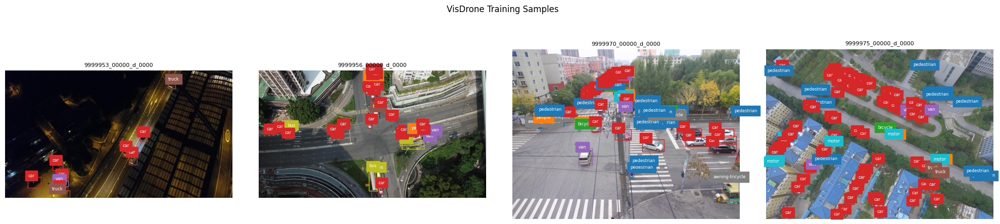


Train class distribution (343205 objects):
  pedestrian          :  79337 (23.1%)
  people              :  27059 (7.9%)
  bicycle             :  10480 (3.1%)
  car                 : 144867 (42.2%)
  van                 :  24956 (7.3%)
  truck               :  12875 (3.8%)
  tricycle            :   4812 (1.4%)
  awning-tricycle     :   3246 (0.9%)
  bus                 :   5926 (1.7%)
  motor               :  29647 (8.6%)

Val class distribution (38759 objects):
  pedestrian          :   8844 (22.8%)
  people              :   5125 (13.2%)
  bicycle             :   1287 (3.3%)
  car                 :  14064 (36.3%)
  van                 :   1975 (5.1%)
  truck               :    750 (1.9%)
  tricycle            :   1045 (2.7%)
  awning-tricycle     :    532 (1.4%)
  bus                 :    251 (0.6%)
  motor               :   4886 (12.6%)


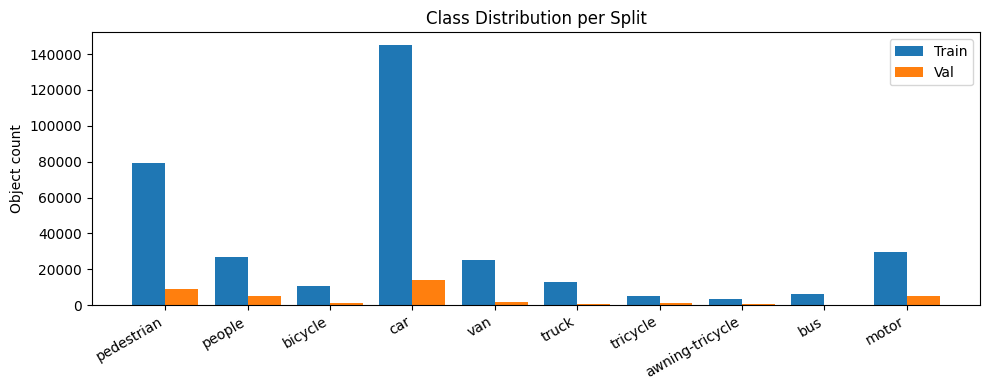

In [4]:
def parse_yolo_label(label_path, img_w, img_h):
    boxes = []
    if not Path(label_path).exists():
        return boxes
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls = int(parts[0])
            cx, cy, bw, bh = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
            x1 = int((cx - bw / 2) * img_w)
            y1 = int((cy - bh / 2) * img_h)
            x2 = int((cx + bw / 2) * img_w)
            y2 = int((cy + bh / 2) * img_h)
            boxes.append((cls, x1, y1, x2, y2))
    return boxes


def visualize_samples(img_dir, lbl_dir, n=4):
    paths  = random.sample(list(img_dir.glob('*.jpg')), n)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    cmap   = plt.colormaps.get_cmap('tab10').resampled(len(VISDRONE_CLASSES))
    for ax, img_path in zip(axes, paths):
        img  = Image.open(img_path).convert('RGB')
        w, h = img.size
        lbl_path = lbl_dir / (img_path.stem + '.txt')
        boxes    = parse_yolo_label(lbl_path, w, h)
        ax.imshow(img)
        for cls, x1, y1, x2, y2 in boxes:
            color = cmap(cls)
            rect  = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                      linewidth=1, edgecolor=color, facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, y1 - 2, VISDRONE_CLASSES[cls], fontsize=6,
                    color='white', backgroundcolor=color)
        ax.axis('off')
        ax.set_title(img_path.name[:20], fontsize=8)
    plt.suptitle('VisDrone Training Samples', fontsize=12)
    plt.tight_layout()
    plt.savefig('/content/dataset_samples.png', dpi=150, bbox_inches='tight')
    plt.show()


def class_distribution(lbl_dir, split_name):
    counts = defaultdict(int)
    for lbl in lbl_dir.glob('*.txt'):
        with open(lbl) as f:
            for line in f:
                parts = line.strip().split()
                if parts:
                    counts[int(parts[0])] += 1
    total = sum(counts.values())
    print(f'\n{split_name} class distribution ({total} objects):')
    for cls_id in sorted(counts):
        pct = 100 * counts[cls_id] / total
        print(f'  {VISDRONE_CLASSES[cls_id]:20s}: {counts[cls_id]:6d} ({pct:.1f}%)')
    return counts


visualize_samples(TRAIN_IMG_DIR, TRAIN_LBL_DIR)

train_counts = class_distribution(TRAIN_LBL_DIR, 'Train')
val_counts   = class_distribution(VAL_LBL_DIR,   'Val')

x = np.arange(len(VISDRONE_CLASSES))
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, [train_counts[i] for i in range(10)], 0.4, label='Train')
plt.bar(x + 0.2, [val_counts[i]   for i in range(10)], 0.4, label='Val')
plt.xticks(x, VISDRONE_CLASSES, rotation=30, ha='right')
plt.ylabel('Object count')
plt.title('Class Distribution per Split')
plt.legend()
plt.tight_layout()
plt.savefig('/content/class_distribution.png', dpi=150)
plt.show()

In [6]:
yaml_content = f'''path: /content/VisDrone/VisDrone_Dataset
train: /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-train/images
val:   /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-val/images
test: /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-dev/images

nc: {len(VISDRONE_CLASSES)}
names: {VISDRONE_CLASSES}
'''

yaml_path = '/content/visdrone.yaml'
with open(yaml_path, 'w') as f:
    f.write(yaml_content)

print("data.yaml written.")
print(yaml_content)

data.yaml written.
path: /content/VisDrone/VisDrone_Dataset
train: /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-train/images
val:   /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-val/images
test: /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-dev/images

nc: 10
names: ['pedestrian', 'people', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'awning-tricycle', 'bus', 'motor']



YOLOv8m Grid Search: 16 configs × 3 probe epochs

[1/16] {'lr0': 0.001, 'batch': 8, 'imgsz': 640, 'optimizer': 'SGD'}
Ultralytics 8.4.48 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi

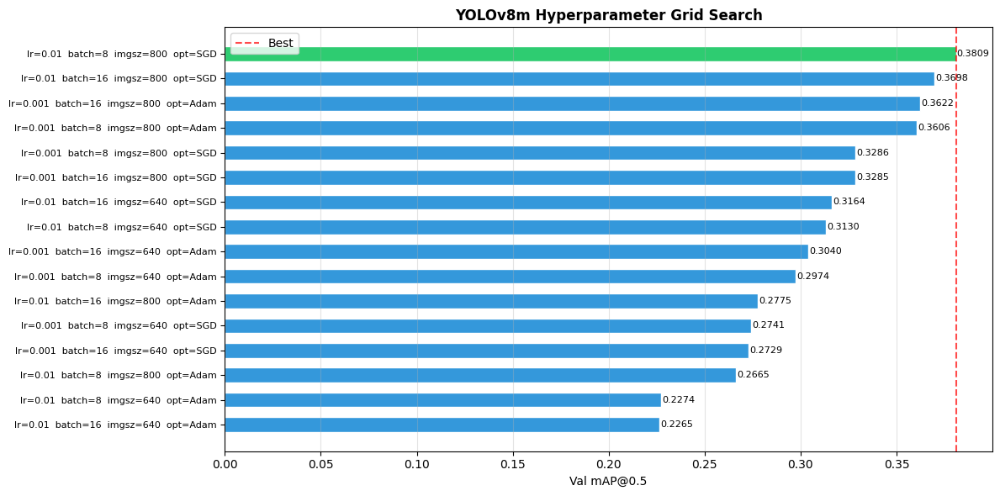

Chart saved: /content/yolo_hp_search.png

Training YOLOv8m with best HP:
  optimizer=SGD, lr0=0.01, batch=8, imgsz=800, epochs=50
Ultralytics 8.4.48 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/visdrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosai

In [9]:
import itertools, shutil

YOLO_HP_SEARCH_EPOCHS = 3
YOLO_HP_PROJECT       = '/content/runs/yolov8_hp'

YOLO_HP_GRID = {
    'lr0':      [0.001, 0.01],
    'batch':    [8, 16],
    'imgsz':    [640, 800],
    'optimizer':['SGD', 'Adam'],
}

keys   = list(YOLO_HP_GRID.keys())
combos = list(itertools.product(*[YOLO_HP_GRID[k] for k in keys]))

yolo_hp_results = []
print(f"YOLOv8m Grid Search: {len(combos)} configs × {YOLO_HP_SEARCH_EPOCHS} probe epochs")
print("=" * 62)

for ci, combo in enumerate(combos, 1):
    params   = dict(zip(keys, combo))
    run_name = f"hp_{ci}"
    print(f"\n[{ci}/{len(combos)}] {params}")

    model = YOLO('yolov8m.pt')
    results = model.train(
        data      = yaml_path,
        epochs    = YOLO_HP_SEARCH_EPOCHS,
        imgsz     = params['imgsz'],
        batch     = params['batch'],
        lr0       = params['lr0'],
        optimizer = params['optimizer'],
        patience  = YOLO_HP_SEARCH_EPOCHS,
        project   = YOLO_HP_PROJECT,
        name      = run_name,
        exist_ok  = True,
        device    = 0 if torch.cuda.is_available() else 'cpu',
        workers   = 2,
        verbose   = False,
        plots     = False,
        save      = True,
        val       = True,
    )

    try:
        val_map = float(results.results_dict.get('metrics/mAP50(B)', 0.0))
    except Exception:
        val_map = 0.0

    print(f"  -> Val mAP@0.5 = {val_map:.4f}")
    yolo_hp_results.append({**params, 'val_mAP': round(val_map, 5)})

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

yolo_hp_results.sort(key=lambda x: x['val_mAP'], reverse=True)
yolo_best_hp = {k: yolo_hp_results[0][k] for k in keys}

yolo_hp_df = pd.DataFrame(yolo_hp_results)
yolo_hp_df.to_csv('/content/yolo_hp_search.csv', index=False)

print("\n" + "─" * 62)
print("Best YOLOv8m config:")
for k, v in yolo_best_hp.items():
    print(f"  {k}: {v}")
print(f"  Val mAP@0.5: {yolo_hp_results[0]['val_mAP']:.4f}")
print("─" * 62)
print("\nFull results:")
print(yolo_hp_df.sort_values('val_mAP', ascending=False).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
sorted_df = yolo_hp_df.sort_values('val_mAP', ascending=False)
labels    = [f"lr={r['lr0']}  batch={r['batch']}  imgsz={r['imgsz']}  opt={r['optimizer']}"
             for _, r in sorted_df.iterrows()]
values    = sorted_df['val_mAP'].values
colors    = ['#2ecc71' if i == 0 else '#3498db' for i in range(len(values))]

bars = ax.barh(range(len(values)), values, color=colors, edgecolor='white', height=0.6)
ax.set_yticks(range(len(values)))
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel('Val mAP@0.5')
ax.set_title('YOLOv8m Hyperparameter Grid Search', fontweight='bold')
ax.axvline(values.max(), color='red', linestyle='--', alpha=0.7, label='Best')
ax.legend()
for bar, val in zip(bars, values):
    ax.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f}', va='center', fontsize=8)
ax.grid(axis='x', alpha=0.35)
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('/content/yolo_hp_search.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved: /content/yolo_hp_search.png")


YOLO_EPOCHS   = 50
YOLO_PATIENCE = 10
YOLO_PROJECT  = '/content/runs/yolov8'

YOLO_IMGSZ = yolo_best_hp['imgsz']
YOLO_BATCH = yolo_best_hp['batch']
YOLO_LR    = yolo_best_hp['lr0']
YOLO_OPT   = yolo_best_hp['optimizer']

print(f"\nTraining YOLOv8m with best HP:")
print(f"  optimizer={YOLO_OPT}, lr0={YOLO_LR}, batch={YOLO_BATCH}, imgsz={YOLO_IMGSZ}, epochs={YOLO_EPOCHS}")

yolo_model   = YOLO('yolov8m.pt')
yolo_results = yolo_model.train(
    data      = yaml_path,
    epochs    = YOLO_EPOCHS,
    imgsz     = YOLO_IMGSZ,
    batch     = YOLO_BATCH,
    lr0       = YOLO_LR,
    optimizer = YOLO_OPT,
    patience  = YOLO_PATIENCE,
    project   = YOLO_PROJECT,
    name      = 'train',
    exist_ok  = True,
    device    = 0 if torch.cuda.is_available() else 'cpu',
    workers   = 2,
    verbose   = True,
    plots     = True,
    save      = True,
    val       = True,
)

YOLO_BEST_WEIGHTS = f'{YOLO_PROJECT}/train/weights/best.pt'
print(f"\nYOLOv8m best weights: {YOLO_BEST_WEIGHTS}")

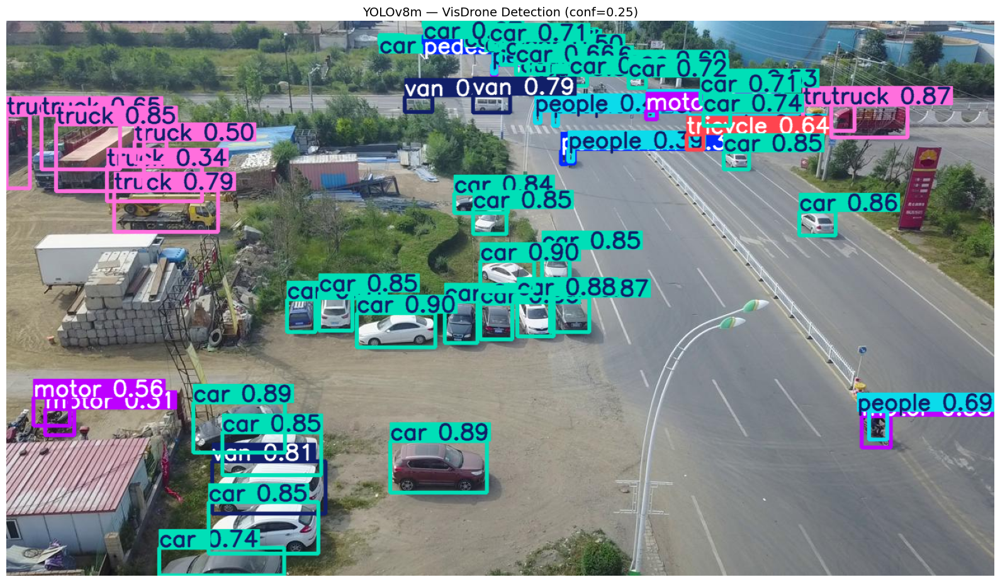

In [11]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('/content/runs/yolov8/train/weights/best.pt')

img_path = '/content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-dev/images/0000006_00611_d_0000002.jpg'

results = model.predict(
    source    = img_path,
    imgsz     = 800,
    conf      = 0.25,
    iou       = 0.45,
    device    = 0,
    save      = False,
    verbose   = False,
)

img = results[0].plot()
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(16, 10))
plt.imshow(img_rgb)
plt.axis('off')
plt.title(f'YOLOv8m — VisDrone Detection (conf=0.25)', fontsize=14)
plt.tight_layout()
plt.savefig('/content/detection_sample.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
yolo_best = YOLO(YOLO_BEST_WEIGHTS)

print("Evaluating YOLOv8m on test set...")
yolo_test_metrics = yolo_best.val(
    data=yaml_path,
    split='test',
    imgsz=YOLO_IMGSZ,
    batch=YOLO_BATCH,
    device=0 if torch.cuda.is_available() else 'cpu',
    verbose=True,
)

yolo_map50     = yolo_test_metrics.box.map50
yolo_map5095   = yolo_test_metrics.box.map
yolo_precision = yolo_test_metrics.box.mp
yolo_recall    = yolo_test_metrics.box.mr

print("YOLOv8m Test Results:")
print(f"  mAP@0.5     : {yolo_map50:.4f}")
print(f"  mAP@0.5:0.95: {yolo_map5095:.4f}")
print(f"  Precision   : {yolo_precision:.4f}")
print(f"  Recall      : {yolo_recall:.4f}")

Evaluating YOLOv8m on test set...
Ultralytics 8.4.48 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 93 layers, 25,845,550 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2794.2±964.7 MB/s, size: 185.2 KB)
val: Scanning /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-dev/labels... 1610 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1610/1610 1.2Kit/s 1.4s
val: New cache created: /content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-dev/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 202/202 12.5it/s 16.1s
                   all       1610      75102      0.529      0.419      0.403      0.237
            pedestrian       1197      21006      0.532      0.382      0.369      0.152
                people        797       6376      0.529      0.183      0.196     0.0695
               bicycle        377       1

There are 1610 listed files in folder: images/


Performing inference on images:   0%|          | 0/1610 [00:00<?, ?it/s]

Performing prediction on 8 slices.


Performing inference on images:   0%|          | 1/1610 [00:00<11:39,  2.30it/s]

Prediction time is: 310.11 ms
Performing prediction on 15 slices.


...

Prediction time is: 251.08 ms
Performing prediction on 8 slices.


Performing inference on images: 100%|█████████▉| 1609/1610 [10:34<00:00,  2.72it/s]

Prediction time is: 237.23 ms
Performing prediction on 15 slices.


Performing inference on images: 100%|██████████| 1610/1610 [10:35<00:00,  2.53it/s]


Prediction time is: 428.10 ms
Prediction results are successfully exported to /content/runs/sahi/test3
Performing prediction on 8 slices.


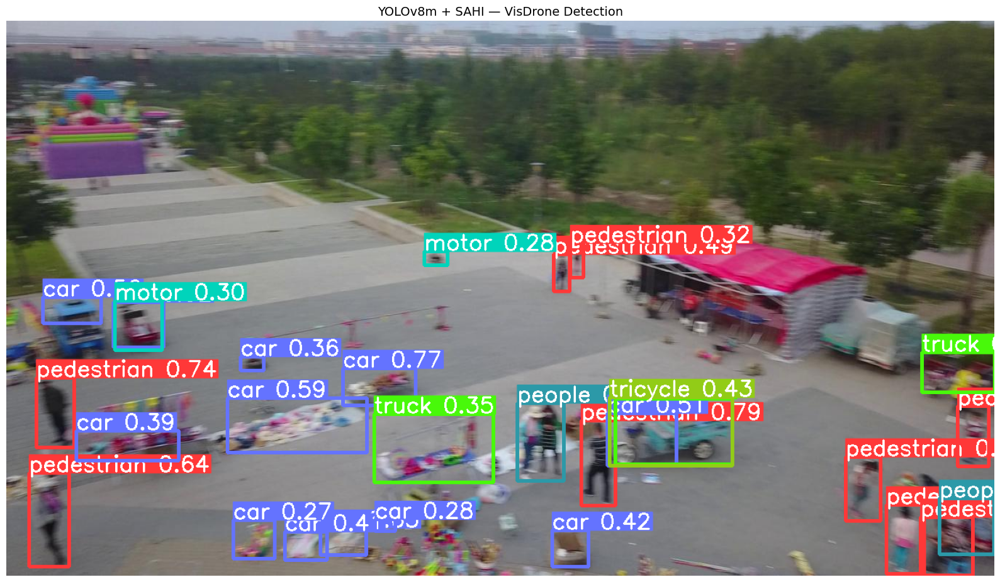

Total detections: 29


In [15]:
!pip install sahi -q

from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction, predict
from sahi.utils.cv import read_image_as_pil
import matplotlib.pyplot as plt
import numpy as np

detection_model = AutoDetectionModel.from_pretrained(
    model_type           = 'ultralytics',
    model_path           = YOLO_BEST_WEIGHTS,
    confidence_threshold = 0.25,
    device               = 'cuda:0',
)

predict(
    detection_model      = detection_model,
    source               = '/content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-dev/images',
    slice_height         = 512,
    slice_width          = 512,
    overlap_height_ratio = 0.2,
    overlap_width_ratio  = 0.2,
    export_pickle        = False,
    export_crop          = False,
    project              = '/content/runs/sahi',
    name                 = 'test',
    visual_bbox_thickness= 1,
    visual_hide_labels   = False,
    visual_hide_conf     = False,
)

sample_img = '/content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-dev/images/0000011_08299_d_0000012.jpg'

result = get_sliced_prediction(
    sample_img,
    detection_model,
    slice_height         = 512,
    slice_width          = 512,
    overlap_height_ratio = 0.2,
    overlap_width_ratio  = 0.2,
)

result.export_visuals(export_dir='/content/runs/sahi/')

img = np.array(read_image_as_pil('/content/runs/sahi/prediction_visual.png'))
plt.figure(figsize=(16, 10))
plt.imshow(img)
plt.axis('off')
plt.title('YOLOv8m + SAHI — VisDrone Detection', fontsize=14)
plt.tight_layout()
plt.savefig('/content/sahi_sample.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Total detections: {len(result.object_prediction_list)}")

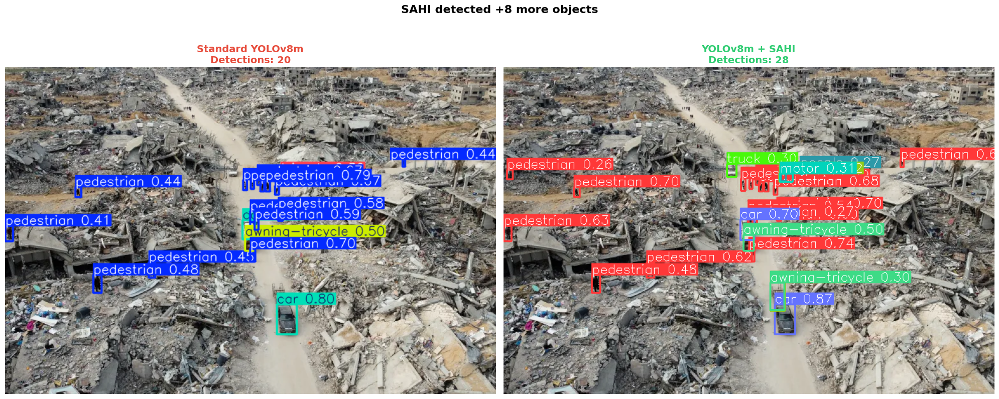

Standard: 20 | SAHI: 28 | Diff: +8


In [21]:
from ultralytics import YOLO
from sahi import AutoDetectionModel
from sahi.predict import get_sliced_prediction
from sahi.utils.cv import read_image_as_pil
import matplotlib.pyplot as plt
import numpy as np
import cv2

sample_img = '/content/reuters_68738ccb-1752403147.webp'

yolo_model  = YOLO(YOLO_BEST_WEIGHTS)
std_results = yolo_model.predict(source=sample_img, imgsz=800, conf=0.25, iou=0.45, device=0, verbose=False)
std_img     = cv2.cvtColor(std_results[0].plot(), cv2.COLOR_BGR2RGB)
std_count   = len(std_results[0].boxes)

detection_model = AutoDetectionModel.from_pretrained(
    model_type='ultralytics', model_path=YOLO_BEST_WEIGHTS,
    confidence_threshold=0.25, device='cuda:0',
)
sahi_result = get_sliced_prediction(sample_img, detection_model,
    slice_height=512, slice_width=512,
    overlap_height_ratio=0.2, overlap_width_ratio=0.2, verbose=0)
sahi_result.export_visuals(export_dir='/content/', file_name='sahi_vis')
sahi_img   = np.array(read_image_as_pil('/content/sahi_vis.png'))
sahi_count = len(sahi_result.object_prediction_list)

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
axes[0].imshow(std_img)
axes[0].set_title(f'Standard YOLOv8m\nDetections: {std_count}', fontsize=14, color='#e74c3c', fontweight='bold')
axes[0].axis('off')
axes[1].imshow(sahi_img)
axes[1].set_title(f'YOLOv8m + SAHI\nDetections: {sahi_count}', fontsize=14, color='#2ecc71', fontweight='bold')
axes[1].axis('off')
fig.suptitle(f'SAHI detected {sahi_count - std_count:+d} more objects', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Standard: {std_count} | SAHI: {sahi_count} | Diff: {sahi_count-std_count:+d}")

In [20]:
class VisDroneDataset(Dataset):
    """
    VisDrone dataset in YOLO format for torchvision detection models.
    Returns image tensors and target dicts with 'boxes' and 'labels'.
    Labels are 1-indexed (0 = background).
    """

    def __init__(self, img_dir, lbl_dir, max_size=640):
        self.img_dir  = Path(img_dir)
        self.lbl_dir  = Path(lbl_dir)
        self.max_size = max_size
        self.imgs     = sorted(self.img_dir.glob('*.jpg'))

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        img_path = self.imgs[idx]
        img      = Image.open(img_path).convert('RGB')
        orig_w, orig_h = img.size

        scale = self.max_size / max(orig_w, orig_h)
        new_w = int(orig_w * scale)
        new_h = int(orig_h * scale)
        img   = img.resize((new_w, new_h), Image.Resampling.LANCZOS)
        img_t = TF.to_tensor(img)

        lbl_path  = self.lbl_dir / (img_path.stem + '.txt')
        raw_boxes = parse_yolo_label(lbl_path, orig_w, orig_h)

        boxes, labels = [], []
        for cls, x1, y1, x2, y2 in raw_boxes:
            x1s, y1s = x1 * scale, y1 * scale
            x2s, y2s = x2 * scale, y2 * scale
            if x2s > x1s and y2s > y1s:
                boxes.append([x1s, y1s, x2s, y2s])
                labels.append(cls + 1)

        if len(boxes) == 0:
            boxes  = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,),   dtype=torch.int64)
        else:
            boxes  = torch.tensor(boxes,  dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)

        return img_t, {'boxes': boxes, 'labels': labels, 'image_id': torch.tensor([idx])}


def collate_fn(batch):
    return tuple(zip(*batch))


PYTORCH_BATCH   = 4
PYTORCH_WORKERS = 2

train_dataset = VisDroneDataset(TRAIN_IMG_DIR, TRAIN_LBL_DIR)
val_dataset   = VisDroneDataset(VAL_IMG_DIR,   VAL_LBL_DIR)
test_dataset  = VisDroneDataset(TEST_IMG_DIR,  TEST_LBL_DIR)

train_loader = DataLoader(train_dataset, batch_size=PYTORCH_BATCH,
                          shuffle=True,  num_workers=PYTORCH_WORKERS, collate_fn=collate_fn)
val_loader   = DataLoader(val_dataset,   batch_size=PYTORCH_BATCH,
                          shuffle=False, num_workers=PYTORCH_WORKERS, collate_fn=collate_fn)
test_loader  = DataLoader(test_dataset,  batch_size=PYTORCH_BATCH,
                          shuffle=False, num_workers=PYTORCH_WORKERS, collate_fn=collate_fn)

print(f"Train batches: {len(train_loader)}")
print(f"Val batches  : {len(val_loader)}")
print(f"Test batches : {len(test_loader)}")

Train batches: 1618
Val batches  : 137
Test batches : 403


In [22]:
def compute_iou(b1, b2):
    xi1 = max(b1[0], b2[0]); yi1 = max(b1[1], b2[1])
    xi2 = min(b1[2], b2[2]); yi2 = min(b1[3], b2[3])
    inter = max(0, xi2 - xi1) * max(0, yi2 - yi1)
    a1    = (b1[2] - b1[0]) * (b1[3] - b1[1])
    a2    = (b2[2] - b2[0]) * (b2[3] - b2[1])
    union = a1 + a2 - inter
    return inter / union if union > 0 else 0.0


def evaluate_map(model, data_loader, device, iou_thresh=0.5, score_thresh=0.05, max_batches=None):
    model.eval()
    all_preds = defaultdict(list)
    all_gts   = defaultdict(list)
    with torch.no_grad():
        for batch_idx, (images, targets) in enumerate(tqdm(data_loader, desc='Evaluating')):
            if max_batches and batch_idx >= max_batches:
                break
            images  = [img.to(device) for img in images]
            outputs = model(images)
            for output, target in zip(outputs, targets):
                pb = output['boxes'].cpu().numpy()
                ps = output['scores'].cpu().numpy()
                pl = output['labels'].cpu().numpy()
                gb = target['boxes'].numpy()
                gl = target['labels'].numpy()
                mask = ps >= score_thresh
                pb, ps, pl = pb[mask], ps[mask], pl[mask]
                all_cls_list = []
                if len(pl) > 0: all_cls_list.append(pl)
                if len(gl) > 0: all_cls_list.append(gl)
                if not all_cls_list:
                    continue
                for cls in np.unique(np.concatenate(all_cls_list)):
                    p_idx = np.where(pl == cls)[0]
                    g_idx = np.where(gl == cls)[0]
                    p_b, p_s = pb[p_idx], ps[p_idx]
                    g_b = gb[g_idx]
                    ord_ = np.argsort(-p_s)
                    p_b, p_s = p_b[ord_], p_s[ord_]
                    matched = [False] * len(g_b)
                    for bi, box in enumerate(p_b):
                        best_iou, best_j = 0, -1
                        for j, gbox in enumerate(g_b):
                            if matched[j]: continue
                            iou = compute_iou(box, gbox)
                            if iou > best_iou:
                                best_iou, best_j = iou, j
                        tp = 1 if (best_iou >= iou_thresh and best_j >= 0) else 0
                        if tp and best_j >= 0:
                            matched[best_j] = True
                        sc = float(p_s[bi])
                        all_preds[cls].append((sc, tp))
                    all_gts[cls].append(len(g_b))
    ap_dict = {}
    for cls in all_gts:
        preds = sorted(all_preds.get(cls, []), key=lambda x: -x[0])
        n_gt  = sum(all_gts[cls])
        if n_gt == 0:
            ap_dict[cls] = 0.0
            continue
        tp_c = np.cumsum([p[1] for p in preds])
        fp_c = np.cumsum([1 - p[1] for p in preds])
        prec = tp_c / (tp_c + fp_c + 1e-9)
        rec  = tp_c / (n_gt + 1e-9)
        mrec  = np.concatenate([[0.], rec,  [1.]])
        mprec = np.concatenate([[0.], prec, [0.]])
        for i in range(len(mprec) - 1, 0, -1):
            mprec[i - 1] = max(mprec[i - 1], mprec[i])
        idx = np.where(mrec[1:] != mrec[:-1])[0]
        ap_dict[cls] = float(np.sum((mrec[idx + 1] - mrec[idx]) * mprec[idx + 1]))
    mean_ap = float(np.mean(list(ap_dict.values()))) if ap_dict else 0.0
    return ap_dict, mean_ap


def train_one_epoch(model, optimizer, data_loader, device, epoch, print_freq=50):
    model.train()
    total_loss = 0.0
    for i, (images, targets) in enumerate(data_loader):
        images  = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        optimizer.step()
        total_loss += loss.item()
        if (i + 1) % print_freq == 0:
            avg = total_loss / (i + 1)
            parts = {k: f'{v.item():.4f}' for k, v in loss_dict.items()}
            print(f'  Epoch {epoch} | Batch {i+1}/{len(data_loader)} | Loss: {avg:.4f} | {parts}')
    return total_loss / len(data_loader)


print("Training utilities ready.")

Training utilities ready.


In [28]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, ssdlite320_mobilenet_v3_large
from torchvision.models.detection import _utils as det_utils
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.ssdlite import SSDLiteClassificationHead
import torch.nn as nn

NUM_CLASSES = 11

def build_faster_rcnn(num_classes):
    model = fasterrcnn_resnet50_fpn_v2(weights='DEFAULT')
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
    return model

def build_ssd_mobilenet(num_classes):
    model = ssdlite320_mobilenet_v3_large(weights='DEFAULT')
    in_channels = det_utils.retrieve_out_channels(model.backbone, (320, 320))
    num_anchors = model.anchor_generator.num_anchors_per_location()
    model.head.classification_head = SSDLiteClassificationHead(
        in_channels, num_anchors, num_classes, nn.BatchNorm2d
    )
    return model

print(f"NUM_CLASSES = {NUM_CLASSES}")
print("build_faster_rcnn   ✅")
print("build_ssd_mobilenet ✅")

NUM_CLASSES = 11
build_faster_rcnn   ✅
build_ssd_mobilenet ✅


In [31]:
import itertools

HP_SEARCH_EPOCHS   = 3
HP_MAX_VAL_BATCHES = 20
MOMENTUM           = 0.9

FRCNN_HP_GRID = {
    'lr':           [0.0001, 0.001],
    'weight_decay': [0.0001, 0.0005],
}

def grid_search(build_fn, hp_grid, train_loader, val_loader, device,
                search_epochs=HP_SEARCH_EPOCHS, max_val_batches=HP_MAX_VAL_BATCHES,
                model_name='Model'):
    keys    = list(hp_grid.keys())
    combos  = list(itertools.product(*[hp_grid[k] for k in keys]))
    results = []

    print(f"\n{'='*62}")
    print(f"  Grid Search: {model_name}  ({len(combos)} configs × {search_epochs} epochs)")
    print(f"{'='*62}")

    for ci, combo in enumerate(combos, 1):
        params = dict(zip(keys, combo))
        print(f"\n[{ci}/{len(combos)}] {params}")

        model = build_fn(NUM_CLASSES).to(device)
        optimizer = optim.SGD(
            [p for p in model.parameters() if p.requires_grad],
            lr           = params['lr'],
            momentum     = MOMENTUM,
            weight_decay = params['weight_decay'],
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=search_epochs)

        for ep in range(1, search_epochs + 1):
            train_one_epoch(model, optimizer, train_loader, device, ep, print_freq=99999)
            scheduler.step()

        _, val_map = evaluate_map(model, val_loader, device, max_batches=max_val_batches)
        print(f"  -> Val mAP@0.5 = {val_map:.4f}")
        results.append({**params, 'val_mAP': round(val_map, 5)})

        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    results.sort(key=lambda x: x['val_mAP'], reverse=True)
    best = {k: results[0][k] for k in keys}

    print(f"\n{'─'*62}")
    print(f"  Best config for {model_name}:")
    for k, v in best.items():
        print(f"    {k}: {v}")
    print(f"  Val mAP@0.5: {results[0]['val_mAP']:.4f}")
    print(f"{'─'*62}")

    df = pd.DataFrame(results).sort_values('val_mAP', ascending=False)
    print("\nAll results:")
    print(df.to_string(index=False))
    return best, df

print("Starting Faster R-CNN HP search ...")
frcnn_best_hp, frcnn_hp_df = grid_search(
    build_faster_rcnn, FRCNN_HP_GRID, train_loader, val_loader, DEVICE,
    model_name='Faster R-CNN')
frcnn_hp_df.to_csv('/content/frcnn_hp_search.csv', index=False)
print(f"\nBest Faster R-CNN HP: {frcnn_best_hp}")

Starting Faster R-CNN HP search ...

  Grid Search: Faster R-CNN  (4 configs × 3 epochs)

[1/4] {'lr': 0.0001, 'weight_decay': 0.0001}


Evaluating:  15%|█▍        | 20/137 [00:02<00:16,  7.02it/s]


  -> Val mAP@0.5 = 0.1986

[2/4] {'lr': 0.0001, 'weight_decay': 0.0005}


Evaluating:  15%|█▍        | 20/137 [00:02<00:16,  6.94it/s]


  -> Val mAP@0.5 = 0.2086

[3/4] {'lr': 0.001, 'weight_decay': 0.0001}


Evaluating:  15%|█▍        | 20/137 [00:02<00:16,  7.04it/s]


  -> Val mAP@0.5 = 0.3631

[4/4] {'lr': 0.001, 'weight_decay': 0.0005}


Evaluating:  15%|█▍        | 20/137 [00:02<00:16,  6.96it/s]


  -> Val mAP@0.5 = 0.3671

──────────────────────────────────────────────────────────────
  Best config for Faster R-CNN:
    lr: 0.001
    weight_decay: 0.0005
  Val mAP@0.5: 0.3671
──────────────────────────────────────────────────────────────

All results:
    lr  weight_decay  val_mAP
0.0010        0.0005  0.36708
0.0010        0.0001  0.36307
0.0001        0.0005  0.20859
0.0001        0.0001  0.19863

Best Faster R-CNN HP: {'lr': 0.001, 'weight_decay': 0.0005}


In [30]:

SSD_HP_GRID = {
    'lr':           [0.005, 0.01],
    'weight_decay': [0.0001, 0.0005],
}

print("Starting SSD MobileNetV3 HP search ...")
ssd_best_hp, ssd_hp_df = grid_search(
    build_ssd_mobilenet, SSD_HP_GRID, train_loader, val_loader, DEVICE,
    model_name='SSD MobileNetV3')
ssd_hp_df.to_csv('/content/ssd_hp_search.csv', index=False)
print(f"\nBest SSD HP: {ssd_best_hp}")

Starting SSD MobileNetV3 HP search ...

  Grid Search: SSD MobileNetV3  (4 configs × 3 epochs)

[1/4] {'lr': 0.005, 'weight_decay': 0.0001}


Evaluating:  15%|█▍        | 20/137 [00:03<00:18,  6.29it/s]


  -> Val mAP@0.5 = 0.0287

[2/4] {'lr': 0.005, 'weight_decay': 0.0005}


Evaluating:  15%|█▍        | 20/137 [00:03<00:19,  6.09it/s]


  -> Val mAP@0.5 = 0.0271

[3/4] {'lr': 0.01, 'weight_decay': 0.0001}


Evaluating:  15%|█▍        | 20/137 [00:03<00:18,  6.41it/s]


  -> Val mAP@0.5 = 0.0347

[4/4] {'lr': 0.01, 'weight_decay': 0.0005}


Evaluating:  15%|█▍        | 20/137 [00:03<00:19,  6.14it/s]

  -> Val mAP@0.5 = 0.0273

──────────────────────────────────────────────────────────────
  Best config for SSD MobileNetV3:
    lr: 0.01
    weight_decay: 0.0001
  Val mAP@0.5: 0.0347
──────────────────────────────────────────────────────────────

All results:
   lr  weight_decay  val_mAP
0.010        0.0001  0.03472
0.005        0.0001  0.02867
0.010        0.0005  0.02729
0.005        0.0005  0.02709

Best SSD HP: {'lr': 0.01, 'weight_decay': 0.0001}


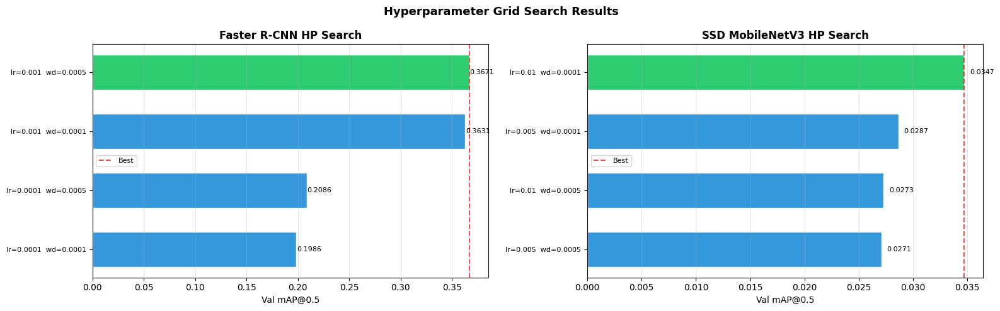

Chart saved: /content/hp_search_results.png


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, df, title in [
    (axes[0], frcnn_hp_df, 'Faster R-CNN HP Search'),
    (axes[1], ssd_hp_df,   'SSD MobileNetV3 HP Search'),
]:
    df_plot = df.reset_index(drop=True)
    labels  = [f"lr={r['lr']}  wd={r['weight_decay']}" for _, r in df_plot.iterrows()]
    colors  = ['#2ecc71' if i == 0 else '#3498db' for i in range(len(df_plot))]
    bars    = ax.barh(range(len(df_plot)), df_plot['val_mAP'].values,
                      color=colors, edgecolor='white', height=0.6)
    ax.set_yticks(range(len(df_plot)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.set_xlabel('Val mAP@0.5')
    ax.set_title(title, fontweight='bold')
    ax.axvline(df_plot['val_mAP'].max(), color='red', linestyle='--',
               alpha=0.7, label='Best')
    ax.legend(fontsize=8)
    for bar, val in zip(bars, df_plot['val_mAP'].values):
        ax.text(bar.get_width() + 0.0005, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)
    ax.grid(axis='x', alpha=0.35)
    ax.invert_yaxis()

plt.suptitle('Hyperparameter Grid Search Results', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/hp_search_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved: /content/hp_search_results.png")


In [37]:
FRCNN_EPOCHS    = 10
FRCNN_SAVE_PATH = '/content/fasterrcnn_best.pth'
frcnn_model = build_faster_rcnn(NUM_CLASSES).to(DEVICE)
frcnn_optimizer = optim.SGD(
    [p for p in frcnn_model.parameters() if p.requires_grad],
    lr           = frcnn_best_hp['lr'],
    momentum     = MOMENTUM,
    weight_decay = frcnn_best_hp['weight_decay'],
)
frcnn_scheduler = optim.lr_scheduler.StepLR(frcnn_optimizer, step_size=5, gamma=0.5)

frcnn_train_losses, frcnn_val_maps, best_frcnn_map = [], [], 0.0

print(f"Retraining Faster R-CNN with: {frcnn_best_hp}")
for epoch in range(1, FRCNN_EPOCHS + 1):
    t0         = time.time()
    train_loss = train_one_epoch(frcnn_model, frcnn_optimizer, train_loader, DEVICE, epoch)
    frcnn_scheduler.step()
    _, val_map = evaluate_map(frcnn_model, val_loader, DEVICE, max_batches=30)
    frcnn_train_losses.append(train_loss)
    frcnn_val_maps.append(val_map)
    elapsed = time.time() - t0
    print(f'Epoch {epoch}/{FRCNN_EPOCHS} | Loss {train_loss:.4f} | Val mAP {val_map:.4f} | {elapsed:.0f}s')
    if val_map > best_frcnn_map:
        best_frcnn_map = val_map
        torch.save(frcnn_model.state_dict(), FRCNN_SAVE_PATH)
        print(f'  [SAVED] new best mAP: {best_frcnn_map:.4f}')

print(f"Faster R-CNN done. Best Val mAP: {best_frcnn_map:.4f}")



Retraining Faster R-CNN with: {'lr': 0.001, 'weight_decay': 0.0005}
  Epoch 1 | Batch 50/1618 | Loss: 2.5836 | {'loss_classifier': '0.6363', 'loss_box_reg': '0.6678', 'loss_objectness': '0.1314', 'loss_rpn_box_reg': '0.2341'}
  Epoch 1 | Batch 100/1618 | Loss: 2.0460 | {'loss_classifier': '0.6412', 'loss_box_reg': '0.5333', 'loss_objectness': '0.5265', 'loss_rpn_box_reg': '0.2318'}
  Epoch 1 | Batch 150/1618 | Loss: 1.8228 | {'loss_classifier': '0.5481', 'loss_box_reg': '0.4707', 'loss_objectness': '0.2840', 'loss_rpn_box_reg': '0.2045'}
  Epoch 1 | Batch 200/1618 | Loss: 1.6971 | {'loss_classifier': '0.4060', 'loss_box_reg': '0.3894', 'loss_objectness': '0.1014', 'loss_rpn_box_reg': '0.1603'}
  Epoch 1 | Batch 250/1618 | Loss: 1.6071 | {'loss_classifier': '0.3037', 'loss_box_reg': '0.2329', 'loss_objectness': '0.0947', 'loss_rpn_box_reg': '0.2318'}
  Epoch 1 | Batch 300/1618 | Loss: 1.5462 | {'loss_classifier': '0.4732', 'loss_box_reg': '0.4800', 'loss_objectness': '0.1180', 'loss_rpn

Evaluating:  22%|██▏       | 30/137 [00:04<00:14,  7.46it/s]


Epoch 1/10 | Loss 1.1399 | Val mAP 0.3022 | 337s
  [SAVED] new best mAP: 0.3022
  Epoch 2 | Batch 50/1618 | Loss: 0.9457 | {'loss_classifier': '0.2091', 'loss_box_reg': '0.2515', 'loss_objectness': '0.0645', 'loss_rpn_box_reg': '0.1985'}
  Epoch 2 | Batch 100/1618 | Loss: 0.9530 | {'loss_classifier': '0.3333', 'loss_box_reg': '0.3188', 'loss_objectness': '0.0717', 'loss_rpn_box_reg': '0.1662'}
  Epoch 2 | Batch 150/1618 | Loss: 0.9327 | {'loss_classifier': '0.3253', 'loss_box_reg': '0.3004', 'loss_objectness': '0.0633', 'loss_rpn_box_reg': '0.1302'}
  Epoch 2 | Batch 200/1618 | Loss: 0.9444 | {'loss_classifier': '0.3279', 'loss_box_reg': '0.3083', 'loss_objectness': '0.0742', 'loss_rpn_box_reg': '0.0754'}
  Epoch 2 | Batch 250/1618 | Loss: 0.9458 | {'loss_classifier': '0.2323', 'loss_box_reg': '0.2953', 'loss_objectness': '0.0578', 'loss_rpn_box_reg': '0.1184'}
  Epoch 2 | Batch 300/1618 | Loss: 0.9453 | {'loss_classifier': '0.2552', 'loss_box_reg': '0.2962', 'loss_objectness': '0.0755

Evaluating:  22%|██▏       | 30/137 [00:03<00:14,  7.56it/s]


Epoch 2/10 | Loss 0.9347 | Val mAP 0.3376 | 337s
  [SAVED] new best mAP: 0.3376
  Epoch 3 | Batch 50/1618 | Loss: 0.8788 | {'loss_classifier': '0.2836', 'loss_box_reg': '0.2982', 'loss_objectness': '0.0654', 'loss_rpn_box_reg': '0.1579'}
  Epoch 3 | Batch 100/1618 | Loss: 0.8992 | {'loss_classifier': '0.3581', 'loss_box_reg': '0.3628', 'loss_objectness': '0.0284', 'loss_rpn_box_reg': '0.2254'}
  Epoch 3 | Batch 150/1618 | Loss: 0.8942 | {'loss_classifier': '0.3244', 'loss_box_reg': '0.3080', 'loss_objectness': '0.0677', 'loss_rpn_box_reg': '0.1263'}
  Epoch 3 | Batch 200/1618 | Loss: 0.8961 | {'loss_classifier': '0.3204', 'loss_box_reg': '0.3360', 'loss_objectness': '0.1122', 'loss_rpn_box_reg': '0.2685'}
  Epoch 3 | Batch 250/1618 | Loss: 0.8938 | {'loss_classifier': '0.2998', 'loss_box_reg': '0.3363', 'loss_objectness': '0.0309', 'loss_rpn_box_reg': '0.1845'}
  Epoch 3 | Batch 300/1618 | Loss: 0.8968 | {'loss_classifier': '0.3459', 'loss_box_reg': '0.3734', 'loss_objectness': '0.0605

...

  Epoch 9 | Batch 50/1618 | Loss: 0.7134 | {'loss_classifier': '0.2840', 'loss_box_reg': '0.3921', 'loss_objectness': '0.0550', 'loss_rpn_box_reg': '0.1962'}
  Epoch 9 | Batch 100/1618 | Loss: 0.7230 | {'loss_classifier': '0.2011', 'loss_box_reg': '0.2928', 'loss_objectness': '0.0272', 'loss_rpn_box_reg': '0.0995'}
  Epoch 9 | Batch 150/1618 | Loss: 0.7310 | {'loss_classifier': '0.2542', 'loss_box_reg': '0.2526', 'loss_objectness': '0.0286', 'loss_rpn_box_reg': '0.1132'}
  Epoch 9 | Batch 200/1618 | Loss: 0.7166 | {'loss_classifier': '0.2124', 'loss_box_reg': '0.3068', 'loss_objectness': '0.0348', 'loss_rpn_box_reg': '0.1125'}
  Epoch 9 | Batch 250/1618 | Loss: 0.7203 | {'loss_classifier': '0.1808', 'loss_box_reg': '0.2702', 'loss_objectness': '0.0682', 'loss_rpn_box_reg': '0.1909'}
  Epoch 9 | Batch 300/1618 | Loss: 0.7170 | {'loss_classifier': '0.2215', 'loss_box_reg': '0.3295', 'loss_objectness': '0.0327', 'loss_rpn_box_reg': '0.0822'}
  Epoch 9 | Batch 350/1618 | Loss: 0.7164 | {'l

Evaluating:  22%|██▏       | 30/137 [00:04<00:14,  7.47it/s]


Epoch 9/10 | Loss 0.7144 | Val mAP 0.4071 | 337s
  [SAVED] new best mAP: 0.4071
  Epoch 10 | Batch 50/1618 | Loss: 0.6911 | {'loss_classifier': '0.1966', 'loss_box_reg': '0.2687', 'loss_objectness': '0.0448', 'loss_rpn_box_reg': '0.1172'}
  Epoch 10 | Batch 100/1618 | Loss: 0.6927 | {'loss_classifier': '0.1988', 'loss_box_reg': '0.3041', 'loss_objectness': '0.0421', 'loss_rpn_box_reg': '0.1552'}
  Epoch 10 | Batch 150/1618 | Loss: 0.6964 | {'loss_classifier': '0.1783', 'loss_box_reg': '0.2210', 'loss_objectness': '0.0670', 'loss_rpn_box_reg': '0.0860'}
  Epoch 10 | Batch 200/1618 | Loss: 0.6909 | {'loss_classifier': '0.2646', 'loss_box_reg': '0.2753', 'loss_objectness': '0.0377', 'loss_rpn_box_reg': '0.1220'}
  Epoch 10 | Batch 250/1618 | Loss: 0.6916 | {'loss_classifier': '0.2461', 'loss_box_reg': '0.2698', 'loss_objectness': '0.0413', 'loss_rpn_box_reg': '0.1227'}
  Epoch 10 | Batch 300/1618 | Loss: 0.6922 | {'loss_classifier': '0.1800', 'loss_box_reg': '0.2497', 'loss_objectness': '

Evaluating:  22%|██▏       | 30/137 [00:04<00:14,  7.48it/s]


Epoch 10/10 | Loss 0.7018 | Val mAP 0.4184 | 337s
  [SAVED] new best mAP: 0.4184
Faster R-CNN done. Best Val mAP: 0.4184


In [40]:
SSD_EPOCHS    = 10
SSD_SAVE_PATH = '/content/ssd_mobilenet_best.pth'

ssd_model     = build_ssd_mobilenet(NUM_CLASSES).to(DEVICE)
ssd_optimizer = optim.SGD(
    [p for p in ssd_model.parameters() if p.requires_grad],
    lr           = ssd_best_hp['lr'],
    momentum     = MOMENTUM,
    weight_decay = ssd_best_hp['weight_decay'],
)
ssd_scheduler = optim.lr_scheduler.CosineAnnealingLR(ssd_optimizer, T_max=SSD_EPOCHS)

ssd_train_losses, ssd_val_maps, best_ssd_map = [], [], 0.0

print(f"\nRetraining SSD MobileNetV3 with: {ssd_best_hp}")
for epoch in range(1, SSD_EPOCHS + 1):
    t0         = time.time()
    train_loss = train_one_epoch(ssd_model, ssd_optimizer, train_loader, DEVICE, epoch)
    ssd_scheduler.step()
    _, val_map = evaluate_map(ssd_model, val_loader, DEVICE, max_batches=30)
    ssd_train_losses.append(train_loss)
    ssd_val_maps.append(val_map)
    elapsed = time.time() - t0
    print(f'Epoch {epoch}/{SSD_EPOCHS} | Loss {train_loss:.4f} | Val mAP {val_map:.4f} | {elapsed:.0f}s')
    if val_map > best_ssd_map:
        best_ssd_map = val_map
        torch.save(ssd_model.state_dict(), SSD_SAVE_PATH)
        print(f'  [SAVED] new best mAP: {best_ssd_map:.4f}')

print(f"SSD done. Best Val mAP: {best_ssd_map:.4f}")



Retraining SSD MobileNetV3 with: {'lr': 0.01, 'weight_decay': 0.0001}
  Epoch 1 | Batch 50/1618 | Loss: 12.7614 | {'bbox_regression': '7.0455', 'classification': '4.6308'}
  Epoch 1 | Batch 100/1618 | Loss: 11.3259 | {'bbox_regression': '5.4762', 'classification': '4.2385'}
  Epoch 1 | Batch 150/1618 | Loss: 10.7343 | {'bbox_regression': '5.9464', 'classification': '3.9510'}
  Epoch 1 | Batch 200/1618 | Loss: 10.4602 | {'bbox_regression': '4.9412', 'classification': '4.2076'}
  Epoch 1 | Batch 250/1618 | Loss: 10.1295 | {'bbox_regression': '5.4254', 'classification': '4.2264'}
  Epoch 1 | Batch 300/1618 | Loss: 9.9838 | {'bbox_regression': '4.3393', 'classification': '3.5101'}
  Epoch 1 | Batch 350/1618 | Loss: 9.8640 | {'bbox_regression': '4.8223', 'classification': '3.7068'}
  Epoch 1 | Batch 400/1618 | Loss: 9.7330 | {'bbox_regression': '3.8555', 'classification': '3.9660'}
  Epoch 1 | Batch 450/1618 | Loss: 9.5976 | {'bbox_regression': '4.6948', 'classification': '3.4446'}
  Epoch

Evaluating:  22%|██▏       | 30/137 [00:04<00:15,  7.08it/s]

Epoch 1/10 | Loss 8.8224 | Val mAP 0.0127 | 139s
  [SAVED] new best mAP: 0.0127


  Epoch 2 | Batch 50/1618 | Loss: 8.0117 | {'bbox_regression': '4.6582', 'classification': '3.7771'}
  Epoch 2 | Batch 100/1618 | Loss: 7.9743 | {'bbox_regression': '4.6660', 'classification': '3.5603'}
  Epoch 2 | Batch 150/1618 | Loss: 8.0459 | {'bbox_regression': '3.3201', 'classification': '3.3795'}
  Epoch 2 | Batch 200/1618 | Loss: 8.1022 | {'bbox_regression': '3.3300', 'classification': '3.3660'}
  Epoch 2 | Batch 250/1618 | Loss: 8.1672 | {'bbox_regression': '4.5442', 'classification': '3.6683'}
  Epoch 2 | Batch 300/1618 | Loss: 8.1840 | {'bbox_regression': '4.0535', 'classification': '3.7889'}
  Epoch 2 | Batch 350/1618 | Loss: 8.1737 | {'bbox_regression': '4.4450', 'classification': '4.0653'}
  Epoch 2 | Batch 400/1618 | Loss: 8.2044 | {'bbox_regression': '4.2000', 'classification': '3.9714'}
  Epoch 2 | Batch 450/1618 | Loss: 8.1721 | {'bbox_regression': '4.5200', 'classification': '3.8118'}
  Epoch 2 | Batch 500/1618 | Loss: 8.1384 | {'bbox_regression': '4.2598', 'classifi

Evaluating:  22%|██▏       | 30/137 [00:04<00:14,  7.34it/s]

...

Evaluating:  22%|██▏       | 30/137 [00:04<00:14,  7.17it/s]

Epoch 9/10 | Loss 6.3560 | Val mAP 0.0253 | 139s
  [SAVED] new best mAP: 0.0253


  Epoch 10 | Batch 50/1618 | Loss: 6.1408 | {'bbox_regression': '2.3785', 'classification': '3.2986'}
  Epoch 10 | Batch 100/1618 | Loss: 6.1948 | {'bbox_regression': '3.2356', 'classification': '3.0976'}
  Epoch 10 | Batch 150/1618 | Loss: 6.2032 | {'bbox_regression': '3.8440', 'classification': '3.3894'}
  Epoch 10 | Batch 200/1618 | Loss: 6.2461 | {'bbox_regression': '2.7772', 'classification': '3.3537'}
  Epoch 10 | Batch 250/1618 | Loss: 6.2178 | {'bbox_regression': '1.9072', 'classification': '2.7525'}
  Epoch 10 | Batch 300/1618 | Loss: 6.2255 | {'bbox_regression': '3.0366', 'classification': '3.1145'}
  Epoch 10 | Batch 350/1618 | Loss: 6.2485 | {'bbox_regression': '2.7796', 'classification': '3.0249'}
  Epoch 10 | Batch 400/1618 | Loss: 6.2655 | {'bbox_regression': '2.9604', 'classification': '3.6792'}
  Epoch 10 | Batch 450/1618 | Loss: 6.2538 | {'bbox_regression': '2.5806', 'classification': '3.3074'}
  Epoch 10 | Batch 500/1618 | Loss: 6.2611 | {'bbox_regression': '2.8693',

Evaluating:  22%|██▏       | 30/137 [00:04<00:15,  7.05it/s]

Epoch 10/10 | Loss 6.2511 | Val mAP 0.0246 | 140s
SSD done. Best Val mAP: 0.0253


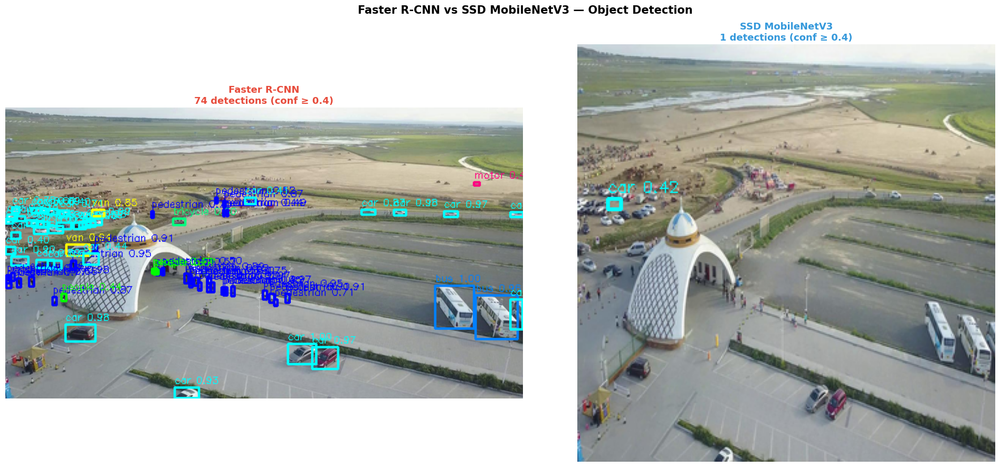

Faster R-CNN: 74 | SSD: 1


In [49]:
import cv2
import matplotlib.pyplot as plt
import torch
from PIL import Image
import torchvision.transforms.functional as TF

CLASS_NAMES = {
    1: 'pedestrian', 2: 'people',    3: 'bicycle',
    4: 'car',        5: 'van',       6: 'truck',
    7: 'tricycle',   8: 'awning-tricycle',
    9: 'bus',       10: 'motor',
}

COLORS = [
    (255,0,0),(0,255,0),(0,0,255),(255,255,0),(0,255,255),
    (255,0,255),(128,255,0),(0,128,255),(255,128,0),(128,0,255),
]

CONF_THRESH     = 0.4
sample_img_path = '/content/VisDrone/VisDrone_Dataset/VisDrone2019-DET-test-challenge/images/0000009_03907_d_0000012.jpg'

img_pil        = Image.open(sample_img_path).convert('RGB')
orig_w, orig_h = img_pil.size
scale          = 640 / max(orig_w, orig_h)
new_w, new_h   = int(orig_w * scale), int(orig_h * scale)
img_resized    = img_pil.resize((new_w, new_h), Image.Resampling.LANCZOS)
img_tensor     = TF.to_tensor(img_resized).unsqueeze(0).to(DEVICE)


def run_detection(model, save_path, model_name, img_size=640):
    """Load model, run inference, return annotated image + count."""
    model.load_state_dict(torch.load(save_path, map_location=DEVICE))
    model.eval()

    if 'SSD' in model_name:
        resized = img_pil.resize((320, 320), Image.Resampling.LANCZOS)
    else:
        resized = img_resized

    tensor = TF.to_tensor(resized).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        outputs = model(tensor)

    output = outputs[0]
    boxes  = output['boxes'].cpu().numpy()
    scores = output['scores'].cpu().numpy()
    labels = output['labels'].cpu().numpy()

    mask   = scores >= CONF_THRESH
    boxes, scores, labels = boxes[mask], scores[mask], labels[mask]

    img_cv = cv2.cvtColor(np.array(resized), cv2.COLOR_RGB2BGR)
    for box, score, label in zip(boxes, scores, labels):
        x1, y1, x2, y2 = map(int, box)
        color    = COLORS[(label - 1) % len(COLORS)]
        cls_name = CLASS_NAMES.get(label, f'cls{label}')
        cv2.rectangle(img_cv, (x1, y1), (x2, y2), color, 2)
        cv2.putText(img_cv, f'{cls_name} {score:.2f}',
                    (x1, max(y1 - 5, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, color, 1)

    return cv2.cvtColor(img_cv, cv2.COLOR_BGR2RGB), len(boxes)


frcnn_img, frcnn_count = run_detection(frcnn_model, FRCNN_SAVE_PATH, 'Faster R-CNN')
ssd_img,   ssd_count   = run_detection(ssd_model,   SSD_SAVE_PATH,   'SSD')

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

axes[0].imshow(frcnn_img)
axes[0].set_title(f'Faster R-CNN\n{frcnn_count} detections (conf ≥ {CONF_THRESH})',
                  fontsize=13, fontweight='bold', color='#e74c3c')
axes[0].axis('off')

axes[1].imshow(ssd_img)
axes[1].set_title(f'SSD MobileNetV3\n{ssd_count} detections (conf ≥ {CONF_THRESH})',
                  fontsize=13, fontweight='bold', color='#3498db')
axes[1].axis('off')

plt.suptitle('Faster R-CNN vs SSD MobileNetV3 — Object Detection',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/frcnn_vs_ssd_detection.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Faster R-CNN: {frcnn_count} | SSD: {ssd_count}")

In [41]:
frcnn_model.load_state_dict(torch.load(FRCNN_SAVE_PATH, map_location=DEVICE))
frcnn_ap_per_class, frcnn_test_map = evaluate_map(frcnn_model, test_loader, DEVICE)

print("Faster R-CNN Test Results:")
print(f"  mAP@0.5: {frcnn_test_map:.4f}")
print("  Per-class AP:")
for cls_id, ap in frcnn_ap_per_class.items():
    name = VISDRONE_CLASSES[cls_id - 1] if 1 <= cls_id <= len(VISDRONE_CLASSES) else f'class_{cls_id}'
    print(f'    {name:20s}: {ap:.4f}')

Evaluating: 100%|██████████| 403/403 [00:44<00:00,  8.96it/s]


Faster R-CNN Test Results:
  mAP@0.5: 0.3007
  Per-class AP:
    pedestrian          : 0.2932
    people              : 0.1269
    car                 : 0.7119
    van                 : 0.3621
    truck               : 0.3627
    tricycle            : 0.1482
    awning-tricycle     : 0.1226
    motor               : 0.2504
    bicycle             : 0.0843
    bus                 : 0.5445


In [42]:
ssd_model.load_state_dict(torch.load(SSD_SAVE_PATH, map_location=DEVICE))
ssd_ap_per_class, ssd_test_map = evaluate_map(ssd_model, test_loader, DEVICE)

print("SSD MobileNetV3 Test Results:")
print(f"  mAP@0.5: {ssd_test_map:.4f}")
print("  Per-class AP:")
for cls_id, ap in ssd_ap_per_class.items():
    name = VISDRONE_CLASSES[cls_id - 1] if 1 <= cls_id <= len(VISDRONE_CLASSES) else f'class_{cls_id}'
    print(f'    {name:20s}: {ap:.4f}')

Evaluating: 100%|██████████| 403/403 [00:52<00:00,  7.68it/s]


SSD MobileNetV3 Test Results:
  mAP@0.5: 0.0193
  Per-class AP:
    pedestrian          : 0.0030
    people              : 0.0008
    car                 : 0.0530
    van                 : 0.0040
    truck               : 0.0432
    bus                 : 0.0843
    motor               : 0.0008
    bicycle             : 0.0002
    tricycle            : 0.0039
    awning-tricycle     : 0.0001


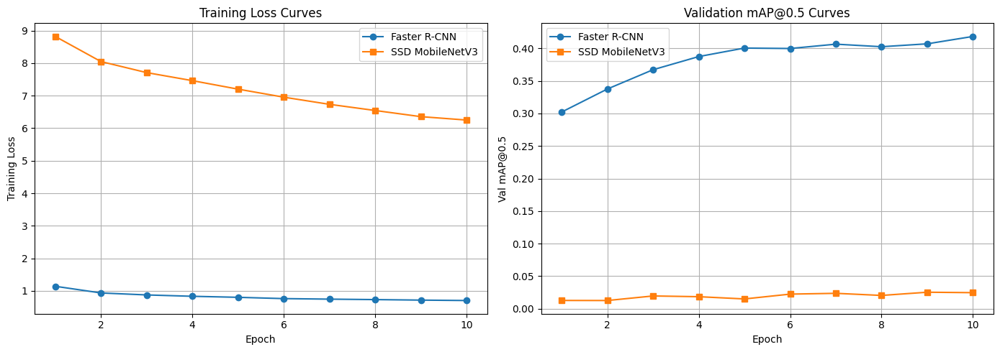

          Model mAP@0.5 (test) mAP@0.5:0.95 Precision Recall Params (M) Inference (ms)
        YOLOv8m         0.4026       0.2374    0.5291 0.4187       25.9            ~18
   Faster R-CNN         0.3007          N/A       N/A    N/A       43.3           25.6
SSD MobileNetV3         0.0193          N/A       N/A    N/A        2.3           19.5
Comparison table saved.


In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

e_f = range(1, FRCNN_EPOCHS + 1)
e_s = range(1, SSD_EPOCHS   + 1)

axes[0].plot(e_f, frcnn_train_losses, marker='o', label='Faster R-CNN')
axes[0].plot(e_s, ssd_train_losses,   marker='s', label='SSD MobileNetV3')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Training Loss')
axes[0].set_title('Training Loss Curves'); axes[0].legend(); axes[0].grid(True)

axes[1].plot(e_f, frcnn_val_maps, marker='o', label='Faster R-CNN')
axes[1].plot(e_s, ssd_val_maps,   marker='s', label='SSD MobileNetV3')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Val mAP@0.5')
axes[1].set_title('Validation mAP@0.5 Curves'); axes[1].legend(); axes[1].grid(True)

plt.tight_layout()
plt.savefig('/content/training_curves.png', dpi=150)
plt.show()


def count_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e6


def inference_speed_ms(model, device, n=50, sz=640):
    model.eval()
    dummy = [torch.rand(3, sz, sz).to(device)]
    with torch.no_grad():
        for _ in range(5): model(dummy)
        t0 = time.time()
        for _ in range(n): model(dummy)
    return (time.time() - t0) / n * 1000


frcnn_speed = inference_speed_ms(frcnn_model, DEVICE, sz=640)
ssd_speed   = inference_speed_ms(ssd_model,   DEVICE, sz=320)

results_df = pd.DataFrame({
    'Model':           ['YOLOv8m',               'Faster R-CNN',           'SSD MobileNetV3'],
    'mAP@0.5 (test)':  [f'{yolo_map50:.4f}',     f'{frcnn_test_map:.4f}',  f'{ssd_test_map:.4f}'],
    'mAP@0.5:0.95':    [f'{yolo_map5095:.4f}',   'N/A',                    'N/A'],
    'Precision':       [f'{yolo_precision:.4f}', 'N/A',                    'N/A'],
    'Recall':          [f'{yolo_recall:.4f}',    'N/A',                    'N/A'],
    'Params (M)':      ['25.9',                  f'{count_params(frcnn_model):.1f}', f'{count_params(ssd_model):.1f}'],
    'Inference (ms)':  ['~18',                   f'{frcnn_speed:.1f}',     f'{ssd_speed:.1f}'],
})

print(results_df.to_string(index=False))
results_df.to_csv('/content/model_comparison.csv', index=False)
print("Comparison table saved.")

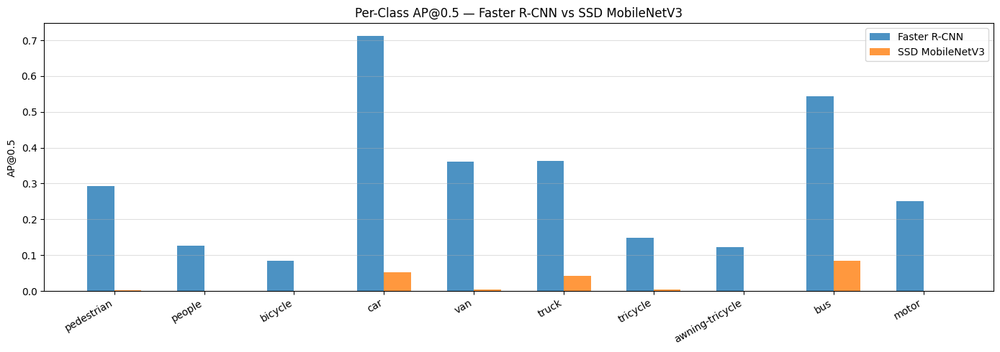

In [50]:
x     = np.arange(len(VISDRONE_CLASSES))
width = 0.3

frcnn_ap_vals = [frcnn_ap_per_class.get(i + 1, 0.0) for i in range(len(VISDRONE_CLASSES))]
ssd_ap_vals   = [ssd_ap_per_class.get(i + 1, 0.0)   for i in range(len(VISDRONE_CLASSES))]

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x - width / 2, frcnn_ap_vals, width, label='Faster R-CNN',    alpha=0.8)
ax.bar(x + width / 2, ssd_ap_vals,   width, label='SSD MobileNetV3', alpha=0.8)
ax.set_xticks(x)
ax.set_xticklabels(VISDRONE_CLASSES, rotation=30, ha='right')
ax.set_ylabel('AP@0.5')
ax.set_title('Per-Class AP@0.5 — Faster R-CNN vs SSD MobileNetV3')
ax.legend(); ax.grid(axis='y', alpha=0.4)
plt.tight_layout()
plt.savefig('/content/per_class_ap.png', dpi=150)
plt.show()

In [55]:
TRACK_CONF       = 0.35
TRACK_IOU        = 0.45
DEEPSORT_MAX_AGE = 30
DEEPSORT_N_INIT  = 3
DEEPSORT_MAX_IOU = 0.7
TRACK_COLORS     = [
    tuple(map(int, color))
    for color in np.random.randint(0, 255, (200, 3), dtype=np.int32)
]


def run_detection_and_tracking(
    video_path, output_path, detector,
    conf=TRACK_CONF, iou=TRACK_IOU, max_frames=None
):
    tracker = DeepSort(
        max_age=DEEPSORT_MAX_AGE,
        n_init=DEEPSORT_N_INIT,
        max_iou_distance=DEEPSORT_MAX_IOU,
        embedder='mobilenet',
        half=True,
        bgr=True,
    )
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise FileNotFoundError(f'Cannot open video: {video_path}')
    W      = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    H      = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps    = cap.get(cv2.CAP_PROP_FPS) or 25.0
    total  = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (W, H))
    history = defaultdict(list)
    frame_n = 0
    print(f'Video: {video_path} | {W}x{H} @ {fps:.1f} fps | {total} frames')
    pbar = tqdm(total=min(total, max_frames or total), desc='Tracking')
    while cap.isOpened():
        ret, frame = cap.read()
        if not ret or (max_frames and frame_n >= max_frames):
            break
        results = detector.predict(frame, conf=conf, iou=iou, verbose=False,
                                   device=0 if torch.cuda.is_available() else 'cpu')
        dets = []
        for r in results:
            for box in r.boxes:
                x1, y1, x2, y2 = box.xyxy[0].tolist()
                dets.append(([x1, y1, x2 - x1, y2 - y1], float(box.conf[0]),
                             VISDRONE_CLASSES[int(box.cls[0])]))
        tracks = tracker.update_tracks(dets, frame=frame)
        for track in tracks:
            if not track.is_confirmed(): continue
            tid     = track.track_id
            tid_int = int(tid) if not isinstance(tid, int) else tid
            x1,y1,x2,y2 = map(int, track.to_ltrb())
            cls_name     = track.det_class if hasattr(track, 'det_class') else 'object'
            color        = TRACK_COLORS[tid_int % len(TRACK_COLORS)]
            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            label = f'ID:{tid_int} {cls_name}'
            (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
            cv2.rectangle(frame, (x1, y1 - th - 4), (x1 + tw, y1), color, -1)
            cv2.putText(frame, label, (x1, y1 - 3),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
            history[tid_int].append((cx, cy))
            if len(history[tid_int]) > 40: history[tid_int].pop(0)
            pts = history[tid_int]
            for i in range(1, len(pts)):
                thick = max(1, int((i / len(pts)) * 3))
                cv2.line(frame, pts[i - 1], pts[i], color, thick)
        active = sum(1 for t in tracks if t.is_confirmed())
        cv2.putText(frame, f'Frame:{frame_n}  Active:{active}', (10, 28),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 0), 2, cv2.LINE_AA)
        writer.write(frame)
        frame_n += 1
        pbar.update(1)
    pbar.close()
    cap.release(); writer.release()
    print(f'Done. {frame_n} frames written to: {output_path}')
    return frame_n


print("DeepSORT tracking function ready.")

DeepSORT tracking function ready.


In [56]:

VIDEO_INPUT  = '/content/trcking video.mp4'
VIDEO_OUTPUT = '/content/tracked_output.mp4'

detector = YOLO(YOLO_BEST_WEIGHTS)

if os.path.exists(VIDEO_INPUT):
    run_detection_and_tracking(
        video_path=VIDEO_INPUT,
        output_path=VIDEO_OUTPUT,
        detector=detector,
        max_frames=300,
    )
else:
    print(f'Video not found: {VIDEO_INPUT}')
    print('Update VIDEO_INPUT to a valid .mp4 path.')

Video: /content/trcking video.mp4 | 848x478 @ 24.0 fps | 345 frames




Tracking:   0%|          | 0/300 [00:00<?, ?it/s]

Tracking:   0%|          | 1/300 [00:00<01:03,  4.69it/s]

Tracking:   1%|          | 3/300 [00:00<00:31,  9.35it/s]

Tracking:   2%|▏         | 5/300 [00:05<06:29,  1.32s/it]

Tracking:   2%|▏         | 6/300 [00:07<07:57,  1.62s/it]

Tracking:   3%|▎         | 8/300 [00:10<07:08,  1.47s/it]

Tracking:   3%|▎         | 10/300 [00:10<04:31,  1.07it/s]

Tracking:   4%|▍         | 12/300 [00:10<03:02,  1.58it/s]

Tracking:   4%|▍         | 13/300 [00:13<04:47,  1.00s/it]

Tracking:   5%|▍         | 14/300 [00:15<06:40,  1.40s/it]

Tracking:   5%|▌         | 16/300 [00:15<04:10,  1.13it/s]

Tracking:   6%|▌         | 18/300 [00:18<04:46,  1.02s/it]

Tracking:   7%|▋         | 20/300 [00:18<03:20,  1.40it/s]

Tracking:   7%|▋         | 22/300 [00:18<02:21,  1.96it/s]

Tracking:   8%|▊         | 24/300 [00:19<01:43,  2.67it/s]

Tracking:   9%|▊         | 26/300 [00:19<01:17,  3.52it/s]

Tracking:   9%|▉         | 28/300 [00:19<01:00,  4.4

Done. 300 frames written to: /content/tracked_output.mp4


---
## Cell 18 — Interactive Inference Interface

In [58]:
import ipywidgets as widgets
from IPython.display import display, clear_output

_yolo_infer  = YOLO(YOLO_BEST_WEIGHTS)
_frcnn_infer = build_faster_rcnn(NUM_CLASSES).to(DEVICE)
_frcnn_infer.load_state_dict(torch.load(FRCNN_SAVE_PATH, map_location=DEVICE))
_frcnn_infer.eval()
_ssd_infer   = build_ssd_mobilenet(NUM_CLASSES).to(DEVICE)
_ssd_infer.load_state_dict(torch.load(SSD_SAVE_PATH, map_location=DEVICE))
_ssd_infer.eval()


def predict_yolo(img_np, conf=0.35):
    results = _yolo_infer.predict(img_np, conf=conf, verbose=False)
    boxes, scores, labels = [], [], []
    for r in results:
        for box in r.boxes:
            boxes.append(box.xyxy[0].tolist())
            scores.append(float(box.conf[0]))
            labels.append(VISDRONE_CLASSES[int(box.cls[0])])
    return boxes, scores, labels


def predict_tv(model, img_np, score_thresh=0.35):
    t   = TF.to_tensor(Image.fromarray(img_np)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = model(t)[0]
    mask   = out['scores'] >= score_thresh
    boxes  = out['boxes'][mask].cpu().numpy().tolist()
    scores = out['scores'][mask].cpu().numpy().tolist()
    labels = [
        VISDRONE_CLASSES[int(l) - 1] if 1 <= int(l) <= len(VISDRONE_CLASSES) else 'unknown'
        for l in out['labels'][mask].cpu().numpy()
    ]
    return boxes, scores, labels


def draw_preds(img_np, boxes, scores, labels):
    img  = img_np.copy()
    cmap = plt.colormaps.get_cmap('tab10').resampled(len(VISDRONE_CLASSES))
    for (x1,y1,x2,y2), score, label in zip(boxes, scores, labels):
        idx   = VISDRONE_CLASSES.index(label) if label in VISDRONE_CLASSES else 0
        color = tuple(int(c * 255) for c in cmap(idx)[:3])
        cv2.rectangle(img, (int(x1),int(y1)), (int(x2),int(y2)), color, 2)
        text = f'{label} {score:.2f}'
        (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, 0.45, 1)
        cv2.rectangle(img, (int(x1), int(y1)-th-4), (int(x1)+tw, int(y1)), color, -1)
        cv2.putText(img, text, (int(x1), int(y1)-3),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255,255,255), 1, cv2.LINE_AA)
    return img


model_sel  = widgets.Dropdown(
    options=['YOLOv8m', 'Faster R-CNN', 'SSD MobileNetV3'],
    description='Model:', layout=widgets.Layout(width='260px')
)
conf_slide = widgets.FloatSlider(
    value=0.35, min=0.05, max=0.95, step=0.05,
    description='Confidence:', layout=widgets.Layout(width='360px')
)
uploader   = widgets.FileUpload(accept='image/*', multiple=False, description='Upload Image')
run_btn    = widgets.Button(description='Run Detection', button_style='primary')
out_area   = widgets.Output()


def on_run(b):
    with out_area:
        clear_output(wait=True)
        if not uploader.value:
            print('Please upload an image first.')
            return
        val = uploader.value
        if isinstance(val, dict):
            content = list(val.values())[0]['content']
        else:
            content = val[0]['content']
        img_np   = np.array(Image.open(io.BytesIO(content)).convert('RGB'))
        conf     = conf_slide.value
        selected = model_sel.value
        print(f'Running {selected}  conf={conf:.2f} ...')
        t0 = time.time()
        if selected == 'YOLOv8m':
            boxes, scores, labels = predict_yolo(img_np, conf)
        elif selected == 'Faster R-CNN':
            boxes, scores, labels = predict_tv(_frcnn_infer, img_np, conf)
        else:
            boxes, scores, labels = predict_tv(_ssd_infer, img_np, conf)
        elapsed = (time.time() - t0) * 1000
        result  = draw_preds(img_np, boxes, scores, labels)
        fig, ax = plt.subplots(1, 2, figsize=(14, 6))
        ax[0].imshow(img_np); ax[0].set_title('Original'); ax[0].axis('off')
        ax[1].imshow(result)
        ax[1].set_title(f'{selected} — {len(boxes)} detections | {elapsed:.1f} ms')
        ax[1].axis('off')
        plt.tight_layout(); plt.show()
        print(f'Detections: {len(boxes)} | Inference: {elapsed:.1f} ms')
        for lbl, sc in zip(labels, scores):
            print(f'  {lbl:20s}: {sc:.3f}')


run_btn.on_click(on_run)

display(widgets.VBox([
    widgets.HTML('<h3>Object Detection Interface — VisDrone</h3>'),
    widgets.HBox([model_sel, conf_slide]),
    uploader, run_btn, out_area,
]))

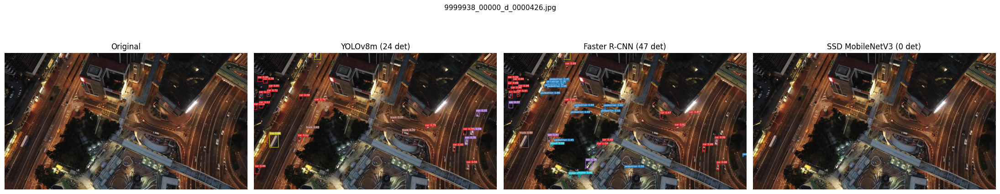

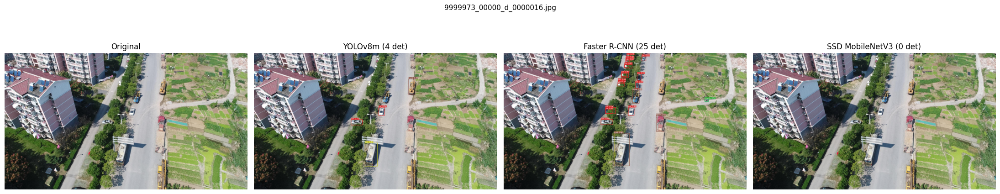

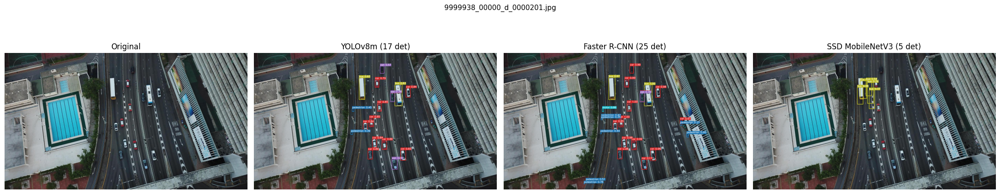

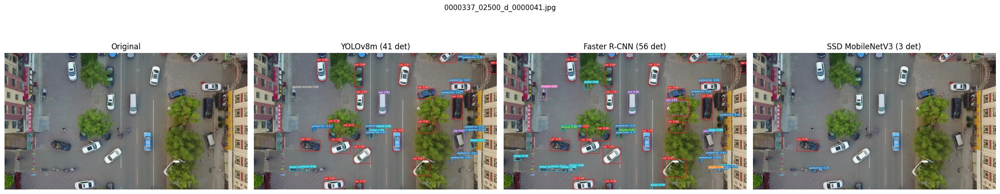

In [59]:
def compare_models_on_image(img_path, conf=0.35):
    img_np = np.array(Image.open(img_path).convert('RGB'))
    y_b, y_s, y_l = predict_yolo(img_np, conf)
    f_b, f_s, f_l = predict_tv(_frcnn_infer, img_np, conf)
    s_b, s_s, s_l = predict_tv(_ssd_infer,   img_np, conf)
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    axes[0].imshow(img_np); axes[0].set_title('Original'); axes[0].axis('off')
    axes[1].imshow(draw_preds(img_np, y_b, y_s, y_l))
    axes[1].set_title(f'YOLOv8m ({len(y_b)} det)'); axes[1].axis('off')
    axes[2].imshow(draw_preds(img_np, f_b, f_s, f_l))
    axes[2].set_title(f'Faster R-CNN ({len(f_b)} det)'); axes[2].axis('off')
    axes[3].imshow(draw_preds(img_np, s_b, s_s, s_l))
    axes[3].set_title(f'SSD MobileNetV3 ({len(s_b)} det)'); axes[3].axis('off')
    plt.suptitle(Path(img_path).name, fontsize=11)
    plt.tight_layout()
    plt.savefig('/content/qualitative_comparison.png', dpi=150)
    plt.show()


for img_path in list(TEST_IMG_DIR.glob('*.jpg'))[:4]:
    compare_models_on_image(img_path)

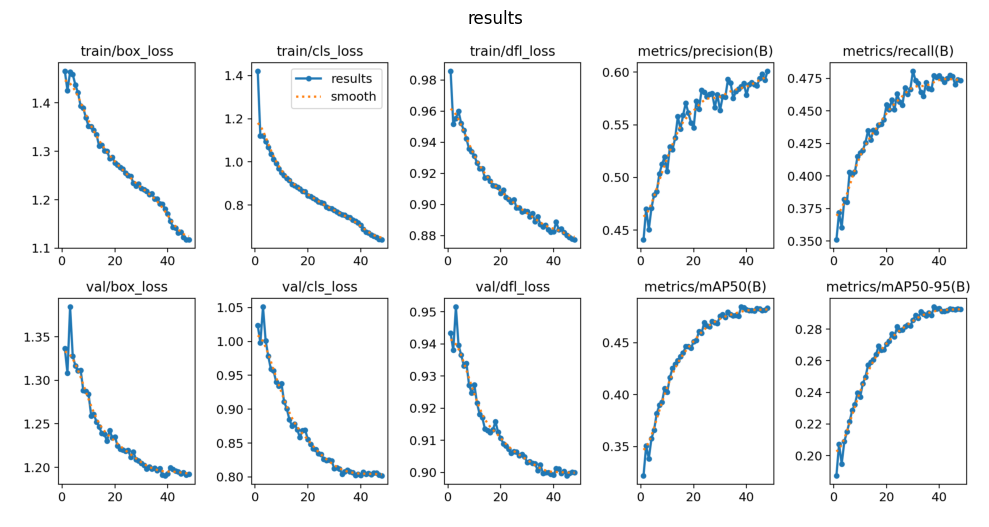

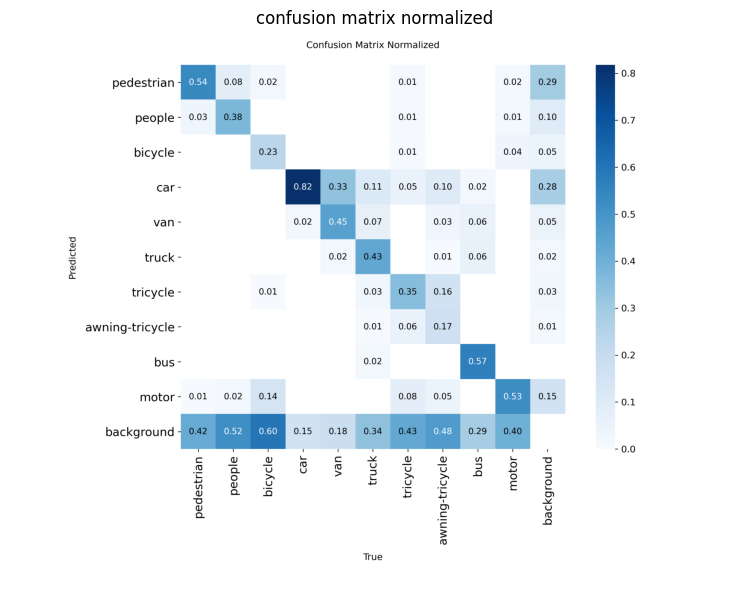

Plot not found: /content/runs/yolov8/train/PR_curve.png


In [60]:
yolo_plot_dir = Path(YOLO_PROJECT) / 'train'
for plot_name in ['results.png', 'confusion_matrix_normalized.png', 'PR_curve.png']:
    plot_path = yolo_plot_dir / plot_name
    if plot_path.exists():
        img = Image.open(plot_path)
        plt.figure(figsize=(10, 6))
        plt.imshow(img); plt.axis('off')
        plt.title(plot_name.replace('_', ' ').replace('.png', ''))
        plt.tight_layout(); plt.show()
    else:
        print(f'Plot not found: {plot_path}')

In [63]:
summary = {
    'YOLOv8m': {
        'mAP@0.5':       round(float(yolo_map50), 4),
        'mAP@0.5:0.95':  round(float(yolo_map5095), 4),
        'precision':     round(float(yolo_precision), 4),
        'recall':        round(float(yolo_recall), 4),
        'epochs':        YOLO_EPOCHS,
        'img_size':      YOLO_IMGSZ,
        'batch':         YOLO_BATCH,
        'lr0':           YOLO_LR,
        'weights_path':  YOLO_BEST_WEIGHTS,
    },
    'Faster_RCNN': {
        'mAP@0.5':      round(frcnn_test_map, 4),
        'epochs':       FRCNN_EPOCHS,
        'lr':           frcnn_best_hp['lr'],
        'momentum':     MOMENTUM,
        'weight_decay': frcnn_best_hp['weight_decay'],
        'weights_path': FRCNN_SAVE_PATH,
    },
    'SSD_MobileNetV3': {
        'mAP@0.5':      round(ssd_test_map, 4),
        'epochs':       SSD_EPOCHS,
        'lr':           ssd_best_hp['lr'],
        'momentum':     MOMENTUM,
        'weight_decay': ssd_best_hp['weight_decay'],
        'weights_path': SSD_SAVE_PATH,
    },
}

with open('/content/results_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print("Results summary saved: /content/results_summary.json")
print(json.dumps(summary, indent=2))

Results summary saved: /content/results_summary.json
{
  "YOLOv8m": {
    "mAP@0.5": 0.4026,
    "mAP@0.5:0.95": 0.2374,
    "precision": 0.5291,
    "recall": 0.4187,
    "epochs": 50,
    "img_size": 800,
    "batch": 8,
    "lr0": 0.01,
    "weights_path": "/content/runs/yolov8/train/weights/best.pt"
  },
  "Faster_RCNN": {
    "mAP@0.5": 0.3007,
    "epochs": 10,
    "lr": 0.001,
    "momentum": 0.9,
    "weight_decay": 0.0005,
    "weights_path": "/content/fasterrcnn_best.pth"
  },
  "SSD_MobileNetV3": {
    "mAP@0.5": 0.0193,
    "epochs": 10,
    "lr": 0.01,
    "momentum": 0.9,
    "weight_decay": 0.0001,
    "weights_path": "/content/ssd_mobilenet_best.pth"
  }
}


In [64]:
def count_params(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

yolo_total     = 25_862_110
yolo_trainable = 25_862_094

frcnn_total, frcnn_trainable = count_params(frcnn_model)
ssd_total,   ssd_trainable   = count_params(ssd_model)

print("=" * 55)
print(f"{'Model':<20} {'Total (M)':>10} {'Trainable (M)':>14}")
print("=" * 55)
print(f"{'YOLOv8m':<20} {yolo_total/1e6:>10.2f} {yolo_trainable/1e6:>14.2f}")
print(f"{'Faster R-CNN':<20} {frcnn_total/1e6:>10.2f} {frcnn_trainable/1e6:>14.2f}")
print(f"{'SSD MobileNetV3':<20} {ssd_total/1e6:>10.2f} {ssd_trainable/1e6:>14.2f}")
print("=" * 55)

Model                 Total (M)  Trainable (M)
YOLOv8m                   25.86          25.86
Faster R-CNN              43.30          43.08
SSD MobileNetV3            2.33           2.33


In [65]:

import os, shutil, json
import torch
from pathlib import Path

EXPORT_DIR = Path('/content/visdrone_models')
EXPORT_DIR.mkdir(exist_ok=True)

yolo_src = Path(YOLO_BEST_WEIGHTS)
yolo_dst = EXPORT_DIR / 'yolov8m_best.pt'
shutil.copy(yolo_src, yolo_dst)
print(f"✓ YOLOv8m   → {yolo_dst}  ({yolo_dst.stat().st_size/1e6:.1f} MB)")

frcnn_dst = EXPORT_DIR / 'fasterrcnn_best.pth'
torch.save(_frcnn_infer.state_dict(), frcnn_dst)
print(f"✓ Faster R-CNN → {frcnn_dst}  ({frcnn_dst.stat().st_size/1e6:.1f} MB)")

ssd_dst = EXPORT_DIR / 'ssd_mobilenet_best.pth'
torch.save(_ssd_infer.state_dict(), ssd_dst)
print(f"✓ SSD MobileNetV3 → {ssd_dst}  ({ssd_dst.stat().st_size/1e6:.1f} MB)")

config = {
    "classes": VISDRONE_CLASSES,
    "num_classes": NUM_CLASSES,
    "weights": {
        "yolo":  "yolov8m_best.pt",
        "frcnn": "fasterrcnn_best.pth",
        "ssd":   "ssd_mobilenet_best.pth",
    }
}
with open(EXPORT_DIR / 'config.json', 'w') as f:
    json.dump(config, f, indent=2)
print(f"✓ config.json saved")

zip_path = '/content/visdrone_models'
shutil.make_archive(zip_path, 'zip', '/content', 'visdrone_models')
print(f"\n Archive ready: {zip_path}.zip")

total_mb = sum(f.stat().st_size for f in EXPORT_DIR.glob('*')) / 1e6
print(f"   Total size: {total_mb:.1f} MB")
print("\nDownloading now...")

from google.colab import files
files.download(f'{zip_path}.zip')
print("Done! Extract the zip and put the folder next to app.py")

✓ YOLOv8m   → /content/visdrone_models/yolov8m_best.pt  (52.0 MB)
✓ Faster R-CNN → /content/visdrone_models/fasterrcnn_best.pth  (173.6 MB)
✓ SSD MobileNetV3 → /content/visdrone_models/ssd_mobilenet_best.pth  (9.6 MB)
✓ config.json saved

✅ Archive ready: /content/visdrone_models.zip
   Total size: 235.3 MB



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Done! Extract the zip and put the folder next to app.py
